<a href="https://colab.research.google.com/github/areyesp-77/intro_nlp/blob/main/session14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sistematización

1.   Análisis de datos
2.   Extracción de características
3.   Clasificación textual



In [ ]:
# Importar librerías
import numpy as np
import sklearn
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.feature_extraction import DictVectorizer
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from google.colab import files


In [ ]:
# Cargamos el DF con los datos positivos y negativos

df = pd.read_csv("hf://datasets/somosnlp-hackathon-2023/suicide-comments-es/suicide_comments_es.csv")
df_positive = df[df['Label']==1]
corpus = df_positive.Text.to_list()


## Técnica 1: BOW

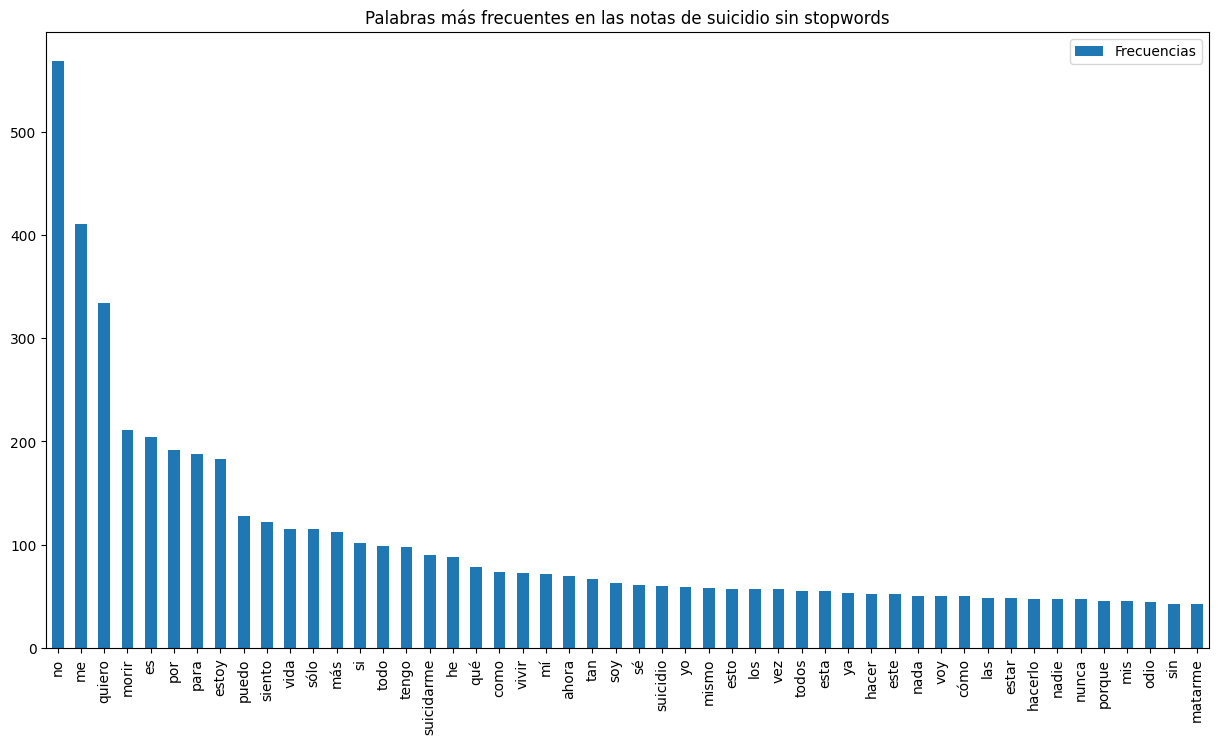

In [ ]:
# Creamos una lista ad hoc de stopwords y la activamos en el vectorizador
# Si tenemos un archivo, cambiamos la variable por el nombre del archivo con las stopwords

stoplist = ['el', 'ella', 'a', 'ante', 'con', 'contra', 'que', 'de', 'un', 'una', 'pero', 'se', 'lo', 'en', 'ante', 'mi', 'la']

vectorizador_clean =  CountVectorizer(stop_words=stoplist, analyzer = 'word')
bow_clean = vectorizador_clean.fit_transform(corpus)

# Matriz de frecuencias
freqs_clean = bow_clean.sum(axis=0)
words_clean = vectorizador_clean.get_feature_names_out()
df_freqs_clean = pd.DataFrame((freqs_clean.T), index=words_clean, columns=['freq'])
#df_freqs_clean.sort_values(by=['freq'], ascending=False)

# Visualización de N palabras más frecuentes con corpus limpio
df_freqs_clean.sort_values(by=['freq'], ascending=False).head(50).plot(kind='bar', figsize=(15,8), title='Palabras más frecuentes en las notas de suicidio sin stopwords')
plt.legend(['Frecuencias'])
#plt.savefig('absolute_freqs_clean.png')
#files.download('absolute_freqs_clean.png')


## Técnica 2: TFIDF

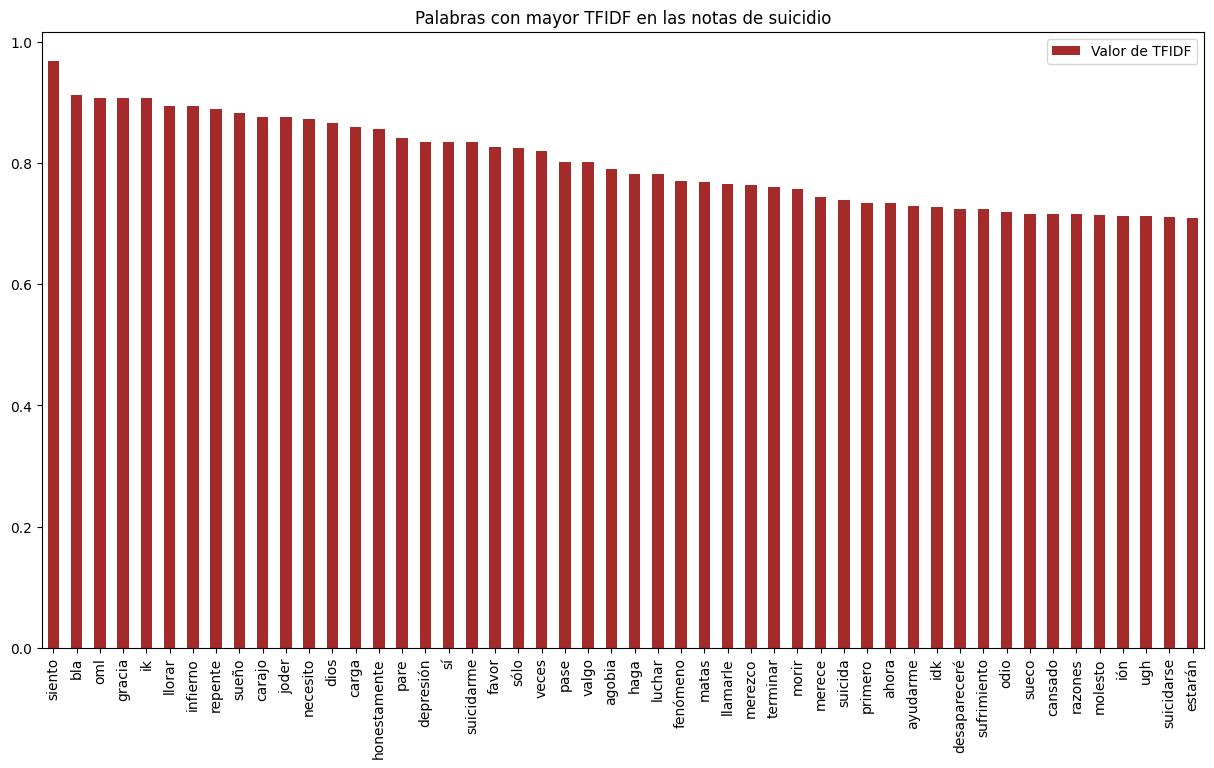

In [ ]:
# Primero instanciamos el método con las stopwords
idf_clean = TfidfVectorizer(stop_words=stoplist, analyzer = 'word')

# Vectorizamos
corpus_idf_clean = idf_clean.fit_transform(corpus)

# Después creamos la matriz ordenada por TFIDF
# En este caso, no traemos las palabras con mayor frecuencia, sino las que tienen mayor tfidf

freqs_idf_clean = corpus_idf_clean.max(axis=0).toarray().ravel()          #cambiamos el método .sum por .max para obtener las de mayor tfidf
words_idf_clean = idf_clean.get_feature_names_out()

df_freqs_idf_clean = pd.DataFrame((freqs_idf_clean), index=words_idf_clean, columns=['max_tfidf'])   #acá filtramos por mayor tfidf
#df_freqs_idf_clean.sort_values(by=['max_tfidf'], ascending=False)

# Visualización
df_freqs_idf_clean.sort_values(by=['max_tfidf'], ascending=False).head(50).plot(kind='bar', figsize=(15,8), title='Palabras con mayor TFIDF en las notas de suicidio', color='brown')
plt.legend(['Valor de TFIDF'])
#plt.savefig('max_tfidf_clean.png')
#files.download('max_tfidf_clean.png')

## N-gramas

Con esta técnica vamos a utilizar valores de 2 a 4. Adicionalmente, vamos a restringir el número de características a los 1000 ngramas más representativos. Adicionalmente, estas características se extraerán considerando solo TF.

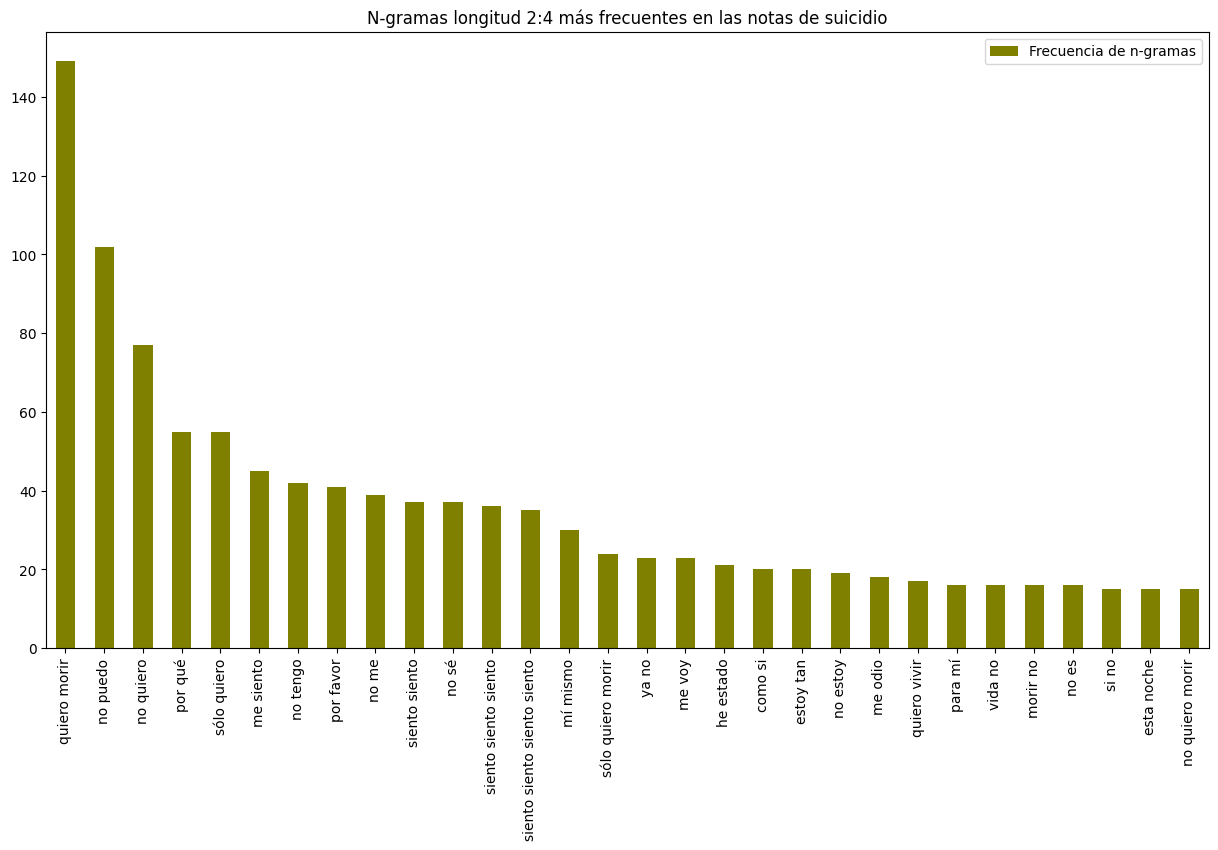

In [ ]:
# Se añade un parámetro para definir el rango de N

vectorizador_clean_n =  CountVectorizer(stop_words=stoplist, analyzer = 'word',
                                      ngram_range=(2,4), max_features=1000)
bow_clean_n = vectorizador_clean_n.fit_transform(corpus)

# Guardamos los resultados en un nuevo DF

freqs_clean_n = bow_clean_n.sum(axis=0)
words_clean_n = vectorizador_clean_n.get_feature_names_out()
df_freqs_clean_n = pd.DataFrame((freqs_clean_n.T), index=words_clean_n, columns=['freq'])
#df_freqs_clean_n.sort_values(by=['freq'], ascending=False)

# Visualizamos
df_freqs_clean_n.sort_values(by=['freq'], ascending=False).head(30).plot(kind='bar', figsize=(15,8), title='N-gramas longitud 2:4 más frecuentes en las notas de suicidio', color='olive')
plt.legend(['Frecuencia de n-gramas'])
#plt.savefig('ngrams_freqs.png')
#files.download('ngrams_freqs.png')

## N-gramas con TFIDF

Mantenemos los mismos valores y restricciones que con la técnica anterior.

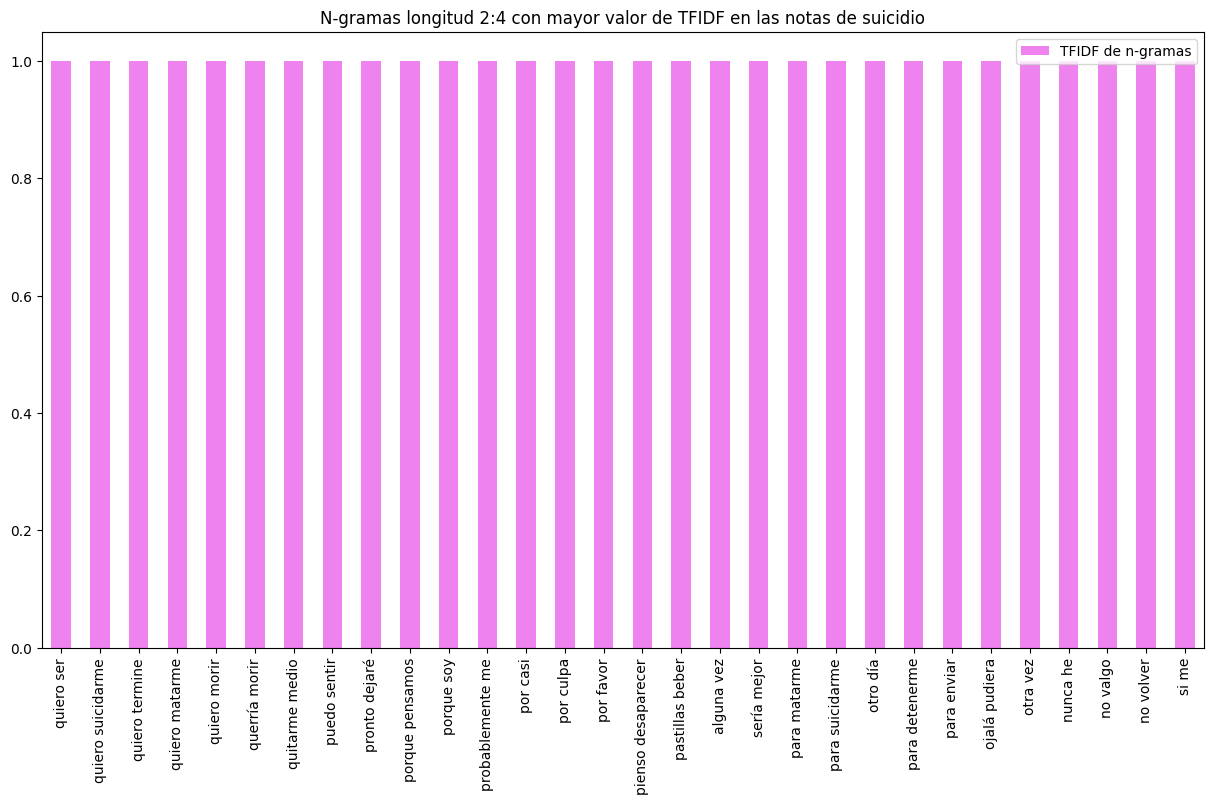

In [ ]:
# Instanciamos el método
idf_clean_n =  TfidfVectorizer(stop_words=stoplist, analyzer = 'word',
                                      ngram_range=(2,4), max_features=1000)

# Vectorizamos
corpus_idf_clean_n = idf_clean_n.fit_transform(corpus)

# Creamos la matriz ordenada por TFIDF

freqs_idf_clean_n = corpus_idf_clean_n.max(axis=0).toarray().ravel()
words_idf_clean_n = idf_clean_n.get_feature_names_out()

df_freqs_idf_clean_n = pd.DataFrame((freqs_idf_clean_n), index=words_idf_clean_n, columns=['max_tfidf'])
#df_freqs_idf_clean_n.sort_values(by=['max_tfidf'], ascending=False)

# Visualizamos

df_freqs_idf_clean_n.sort_values(by=['max_tfidf'], ascending=False).head(30).plot(kind='bar', figsize=(15,8),
                                                                                  title='N-gramas longitud 2:4 con mayor valor de TFIDF en las notas de suicidio',
                                                                                  color='violet')
plt.legend(['TFIDF de n-gramas'])
#plt.savefig('ngrams_idf.png')
#files.download('ngrams_idf.png')

## Comparación de características



In [ ]:
# Creamos una lista con los resultados de cada técnica
dfs = [df_freqs_clean, df_freqs_idf_clean, df_freqs_clean_n, df_freqs_idf_clean_n]

# Creamos una lista vacía en donde se guardarán las características
features = []

# Iteramos sobre los DFs para traer las características
for i, df_temp in enumerate(dfs):
    col_name = df_temp.columns[0]
    df_sorted = df_temp.sort_values(by=col_name, ascending=False)
    features.append(pd.Series(df_sorted.index, name=f'Características{i+1}'))

# Creamos un DF para concatenar las características
df_comparisson = pd.concat(features, axis=1)
df_comparisson.columns = [
    'BOW',
    'Max_TFIDF',
    'Ngrams',
    'Max_TFIDF_Ngrmas'
]

display(df_comparisson.head(30))

#df_comparisson.to_csv('features.csv', index=False)
#files.download('features.csv')

,BOW,Max_TFIDF,Ngrams,Max_TFIDF_Ngrmas
0,no,siento,quiero morir,quiero ser
1,me,bla,no puedo,quiero suicidarme
2,quiero,oml,no quiero,quiero termine
3,morir,gracia,por qué,quiero matarme
4,es,ik,sólo quiero,quiero morir
5,por,llorar,me siento,querría morir
6,para,infierno,no tengo,quitarme medio
7,estoy,repente,por favor,puedo sentir
8,puedo,sueño,no me,pronto dejaré
9,siento,carajo,siento siento,porque pensamos


## Task 2: clasificación textual

Esta tarea de PLN busca que un modelo X identifique las características más discriminantes entre clases (en el caso del ejercicio, dos clases) para clasificar un texto como nota de suicidio (dato positivo) o de no suicidio (dato negativo).

El escenario que supone la tarea implica que hay que trabajar con datos positivos y negativos al mismo tiempo. Ello signfica que los documentos que tienen la etiqueta 1 deben ser lo suficientemente representativos de lo que puede entenderse como una nota de suicidio. Asimismo, los datos negativos deben ser claros ejemplos de aquello que no es una nota de suicidio. En conjunto, tanto datos positivos como negativos deben tender a discriminarse entre sí.

Ahora bien, en el contexto de clasificación textual, el modelo debe aprender claramente qué caracteriza a los datos positivos para poder separarlos de los negativos. Para ello, en PLN se acostumbra dividir el dataset en dos particiones: **training** y **test**.

El training sirve para observar cómo se comporta el modelo en la extracción de características, en tanto que el test sirve para evaluar la calidad del modelo. Las métricas que hemos visto en clase se aplican al desempeño que tiene el modelo en la partición de test.

Nota: se acostumbra dividir el dataset en 70% training y 30% test. Finalmente, señalar que el test nunca se ve, solo sirve para evaluar datos que el modelo no conoce.

In [ ]:
# Dividimos el DF en training y test usando el método train_test_split de sklearn

x_train, x_test, y_train, y_test = train_test_split(df.Text, df.Label, test_size=0.3, random_state=42)

# Ver el tamaño de documentos de cada partición
print(f'Training: {x_train.shape}, Test: {x_test.shape}')

# Verificamos cómo queda la partición de training en términos de muestras positivas y negativas

print('Tamaño de clases en training:')
print(y_train.value_counts())



Training: (7035,), Test: (3015,)
Tamaño de clases en training:
Label
0    6495
1     540
Name: count, dtype: int64


## Entrenamiento de modelo de clasificación



In [ ]:
# Importamos el módulo de clasificación de Bayes
from sklearn.naive_bayes import MultinomialNB


In [ ]:
# Definimos las técnicas que usaremos para la extracción de características

vectorizadores = {
    "BOW": CountVectorizer(stop_words=stoplist, analyzer = 'word', max_features=1000),
    "TFIDF": TfidfVectorizer(stop_words=stoplist, analyzer = 'word', max_features=1000),
    "N-grams": CountVectorizer(stop_words=stoplist, analyzer = 'word', ngram_range=(2,4), max_features=1000),
    "IDF-grams": TfidfVectorizer(stop_words=stoplist, analyzer = 'word', ngram_range=(2,4), max_features=1000)
}


 Técnica BOW
Accuracy: 0.9373

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.99      0.94      0.97      2778
           1       0.56      0.92      0.70       237

    accuracy                           0.94      3015
   macro avg       0.78      0.93      0.83      3015
weighted avg       0.96      0.94      0.94      3015



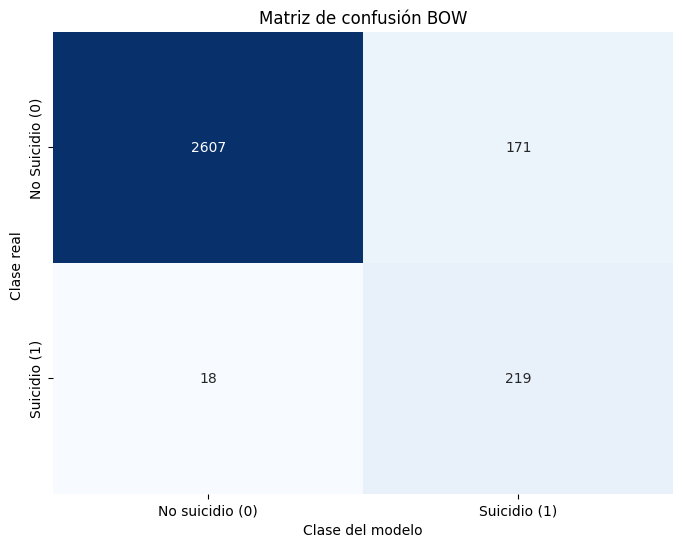

In [ ]:
# Clasificador con BOW

# Vectorización de training con la técnica de BOW llamando el vectorizador por su ID
x_train_vec = vectorizadores["BOW"].fit_transform(x_train)

# Vectorización de test
# Nota: no usar NUNCA el método fit en test, ese es solo para training
x_test_vec = vectorizadores["BOW"].transform(x_test)

# Inicializar el clasificador
# Nota: tal como se mencionó, usaremos el algoritmo de Bayes. La forma de llamarlo en sklearn es MultinomialNB()
# Nota: para el modelado, usamos ambas particiones (x,y: training,test)

modelo_bow = MultinomialNB()
modelo_bow.fit(x_train_vec, y_train)

# Clasificación
y_pred = modelo_bow.predict(x_test_vec)

# Resultados
acc = accuracy_score(y_test, y_pred)
print('\n' + '='*50)
print(f' Técnica BOW')
print('='*50)

print(f'Accuracy: {acc:.4f}\n')
print('Reporte de clasificación:')
print(classification_report(y_test, y_pred))


# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No suicidio (0)', 'Suicidio (1)'],
                yticklabels=['No Suicidio (0)', 'Suicidio (1)'])
plt.title(f'Matriz de confusión BOW')
plt.ylabel('Clase real ')
plt.xlabel('Clase del modelo')
plt.show()



 Técnica TFIDF
Accuracy: 0.9625

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      2778
           1       0.86      0.62      0.72       237

    accuracy                           0.96      3015
   macro avg       0.92      0.81      0.85      3015
weighted avg       0.96      0.96      0.96      3015



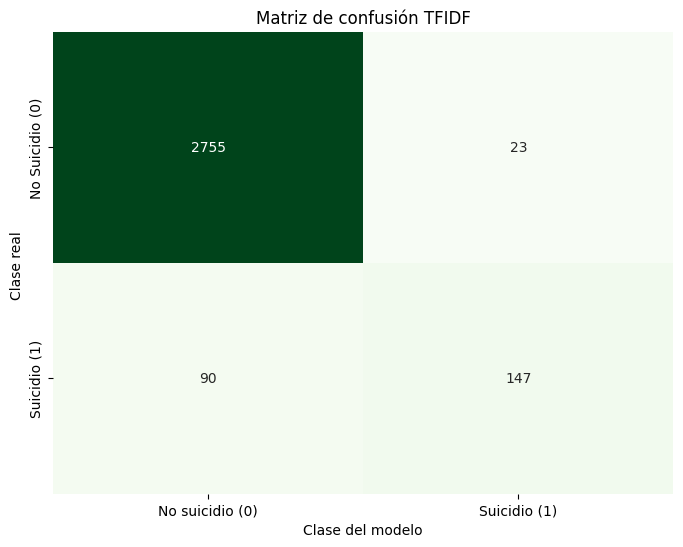

In [ ]:
# Clasificador con TFIDF

# Vectorización de training con la técnica de TFIDF
x_train_vec = vectorizadores["TFIDF"].fit_transform(x_train)

# Vectorización de test
# Nota: no usar NUNCA el método fit en test, ese es solo para training
x_test_vec = vectorizadores["TFIDF"].transform(x_test)

# Inicializar el clasificador
modelo_bow = MultinomialNB()
modelo_bow.fit(x_train_vec, y_train)

# Clasificación
y_pred = modelo_bow.predict(x_test_vec)

# Resultados
acc = accuracy_score(y_test, y_pred)
print('\n' + '='*50)
print(f' Técnica TFIDF')
print('='*50)

print(f'Accuracy: {acc:.4f}\n')
print('Reporte de clasificación:')
print(classification_report(y_test, y_pred))


# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False,
                xticklabels=['No suicidio (0)', 'Suicidio (1)'],
                yticklabels=['No Suicidio (0)', 'Suicidio (1)'])
plt.title(f'Matriz de confusión TFIDF')
plt.ylabel('Clase real ')
plt.xlabel('Clase del modelo')
plt.show()


 Técnica N-gramas
Accuracy: 0.9489

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      2778
           1       0.71      0.59      0.64       237

    accuracy                           0.95      3015
   macro avg       0.84      0.78      0.81      3015
weighted avg       0.95      0.95      0.95      3015



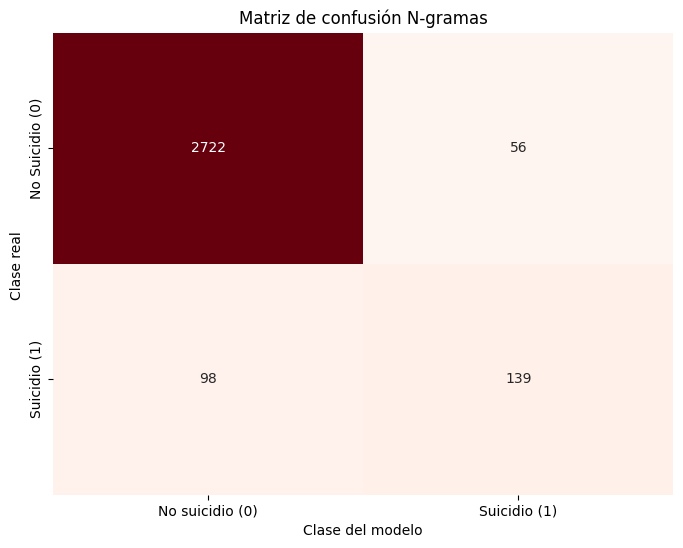

In [ ]:
# Clasificador con N-gramas (2-4)

# Vectorización de training con la técnica de N-gramas
x_train_vec = vectorizadores["N-grams"].fit_transform(x_train)

# Vectorización de test
# Nota: no usar NUNCA el método fit en test, ese es solo para training
x_test_vec = vectorizadores["N-grams"].transform(x_test)

# Inicializar el clasificador
modelo_bow = MultinomialNB()
modelo_bow.fit(x_train_vec, y_train)

# Clasificación
y_pred = modelo_bow.predict(x_test_vec)

# Resultados
acc = accuracy_score(y_test, y_pred)
print('\n' + '='*50)
print(f' Técnica N-gramas')
print('='*50)

print(f'Accuracy: {acc:.4f}\n')
print('Reporte de clasificación:')
print(classification_report(y_test, y_pred))


# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False,
                xticklabels=['No suicidio (0)', 'Suicidio (1)'],
                yticklabels=['No Suicidio (0)', 'Suicidio (1)'])
plt.title(f'Matriz de confusión N-gramas')
plt.ylabel('Clase real ')
plt.xlabel('Clase del modelo')
plt.show()


 Técnica TFIDF de N-gramas
Accuracy: 0.9502

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.95      1.00      0.97      2778
           1       0.90      0.41      0.57       237

    accuracy                           0.95      3015
   macro avg       0.93      0.70      0.77      3015
weighted avg       0.95      0.95      0.94      3015



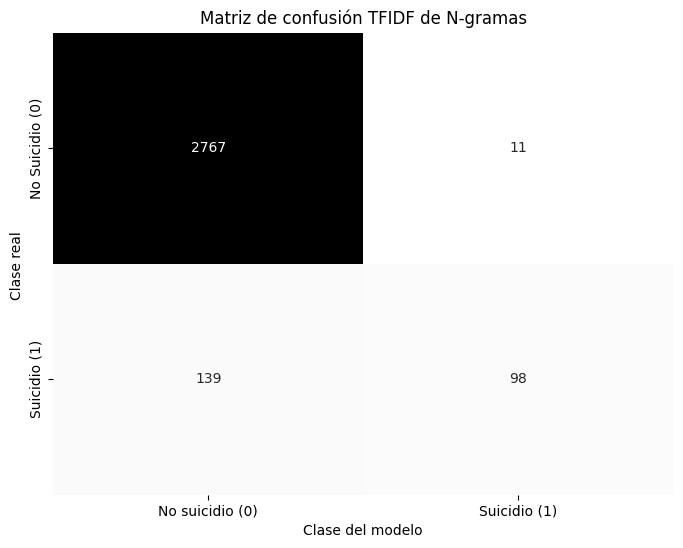

In [ ]:
# Clasificador con TFIDF de N-gramas

# Vectorización de training con la técnica de TFIDF de n-gramas
x_train_vec = vectorizadores["IDF-grams"].fit_transform(x_train)

# Vectorización de test
# Nota: no usar NUNCA el método fit en test, ese es solo para training
x_test_vec = vectorizadores["IDF-grams"].transform(x_test)

# Inicializar el clasificador
modelo_bow = MultinomialNB()
modelo_bow.fit(x_train_vec, y_train)

# Clasificación
y_pred = modelo_bow.predict(x_test_vec)

# Resultados
acc = accuracy_score(y_test, y_pred)
print('\n' + '='*50)
print(f' Técnica TFIDF de N-gramas')
print('='*50)

print(f'Accuracy: {acc:.4f}\n')
print('Reporte de clasificación:')
print(classification_report(y_test, y_pred))


# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Grays', cbar=False,
                xticklabels=['No suicidio (0)', 'Suicidio (1)'],
                yticklabels=['No Suicidio (0)', 'Suicidio (1)'])
plt.title(f'Matriz de confusión TFIDF de N-gramas')
plt.ylabel('Clase real ')
plt.xlabel('Clase del modelo')
plt.show()



---






# Incorporación de características personales

Vamos a suponer que, además de las técnicas usadas, identificamos un conjunto de características distintas para modelar el fenómeno. Estas características son:

1. Longitud del documento
2. Polaridad del documento
3. Conteo de verbos por documento
4. Referencias pronominales


Notar que estas características no implican un procesamiento distinto del corpus, pues todas ellas se pueden identificar mediante métodos o librerías que conocemos; por lo tanto, vamos a crear un código para identifcarlas en el documento y, posteriormente, vectorizar.

In [ ]:
# Instalamos las librerías que vamos a usar

!pip install pysentimiento
from pysentimiento import create_analyzer
analyser = create_analyzer(task="sentiment", lang="es")

import spacy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 11.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [pysentimiento]


config.json:   0%|          | 0.00/925 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  435MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/384 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.31M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

In [ ]:
# Cargamos el modelo de español de spaCy (desactivamos componentes pesados que no usaremos)
!python -m spacy download es_core_news_sm
nlp = spacy.load("es_core_news_sm", disable=["parser", "lemmatizer"])

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 85.1 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
# Creamos una función para vectorizar las características e incorporarlas a las previas

from sklearn.base import BaseEstimator, TransformerMixin

class AdvancedFeaturesExtractor(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        length = []
        polarity = []
        verb = []
        properN = []

        # Primero obtenemos las predicciones de polaridad con pysentimiento
        texts_list = list(X)
        sentiment_results = analyser.predict(texts_list)

        for res in sentiment_results:
            # La polaridad se asigna con un valor continuo en el rango [-1.0, 1.0]
            probas = res.probas
            score = probas.get('POS', 0.0) - probas.get('NEG', 0.0)
            polarity.append(score)

        # Conteo de verbos y PROPNs con spaCy
        for doc in nlp.pipe(X, batch_size=100):
            length.append(len(doc.text))
            verbs = sum(1 for token in doc if token.pos_ in ['VERB'])
            propn = sum(1 for token in doc if token.pos_ == 'PROPN')
            verb.append(verbs)
            properN.append(propn)

        return np.vstack((length, polarity, verb, properN)).T

In [ ]:
# Instanciamos el extractor de características
extractor_linguistico = AdvancedFeaturesExtractor()

# Tomamos las primeras N muestras de nuestro dataset para el análisis
muestras_analisis = df.Text.head(10)

# Extraemos las características
matriz_caracteristicas = extractor_linguistico.transform(muestras_analisis)

# Creamos un DF para visualizar los resultados
df_analisis_caracteristicas = pd.DataFrame(
    matriz_caracteristicas,
    columns=['Longitud', 'Polaridad', 'Num_Verbos', 'Num_Nombres_Propios']
)

# Añadimos el inicio del documento para la comparativa visual
df_analisis_caracteristicas.insert(0, 'Documento', muestras_analisis.str[:50] + '...') # Doc truncado

# Mostrar el DataFrame con los resultados detallados
display(df_analisis_caracteristicas)

Map:   0%|          | 0/10 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


,Documento,Longitud,Polaridad,Num_Verbos,Num_Nombres_Propios
0,Pablo Picasso es un artista famoso de principi...,62.0,0.312288,0.0,2.0
1,"Las mujeres son extrañas, sé lo que quieres de...",88.0,-0.747245,4.0,0.0
2,"import datetime\ncadenaFechaHora = ""20/08/2020...",234.0,-0.004618,3.0,4.0
3,Coursera.org...,12.0,0.104869,0.0,1.0
4,Dime quién fue la primera celebridad en ganar ...,72.0,0.115627,1.0,4.0
5,Sugiere una actividad romántica para la noche...,45.0,0.486981,1.0,0.0
6,Crea una lista de 5 verbos que podrían usarse ...,78.0,0.162708,4.0,0.0
7,Solo pienso en desaparecer...,26.0,-0.578370,2.0,0.0
8,"No es lo más fácil de hacer, me alivia cuando ...",182.0,0.819884,6.0,1.0
9,La máquina fue diseñada por el ingeniero....,41.0,0.171264,1.0,0.0


Iniciando el entrenamiento del modelo unificado


Map:   0%|          | 0/7035 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


¡Modelo entrenado exitosamente!


Map:   0%|          | 0/3015 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



 Reporte de clasificación - Modelo unificado
              precision    recall  f1-score   support

           0       0.99      0.96      0.98      2778
           1       0.68      0.92      0.78       237

    accuracy                           0.96      3015
   macro avg       0.84      0.94      0.88      3015
weighted avg       0.97      0.96      0.96      3015



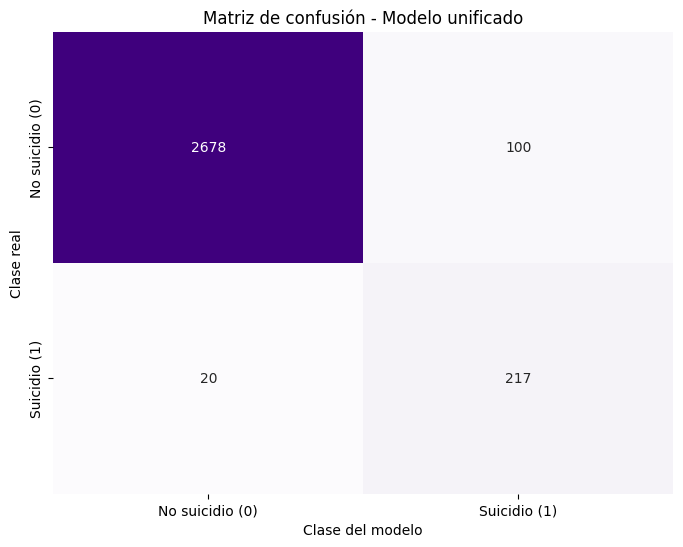

In [ ]:
# Combinación de características

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Definimos la unión de características para integrar todo en un solo vector por documento
caracteristicas_unificadas = FeatureUnion(
    transformer_list=[
        ('bow', CountVectorizer(stop_words=stoplist, max_features=1000)),
        ('tfidf', TfidfVectorizer(stop_words=stoplist, max_features=1000)),
        ('ngrams_bow', CountVectorizer(stop_words=stoplist, ngram_range=(2,4), max_features=1000)),
        ('ngrams_tfidf', TfidfVectorizer(stop_words=stoplist, ngram_range=(2,4), max_features=1000)),
        ('linguisticas', Pipeline([
            ('extractor', AdvancedFeaturesExtractor()),
            ('scaler', StandardScaler())
        ]))
    ]
)

# Usamos un clasificador de regresión logística
pipeline_clasificador = Pipeline([
    ('union_caracteristicas', caracteristicas_unificadas),
    ('clasificador', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])

# Entrenamos el model completo utilizando el conjunto de entrenamiento
print("Iniciando el entrenamiento del modelo unificado")
pipeline_clasificador.fit(x_train, y_train)
print("¡Modelo entrenado exitosamente!")

# Evaluación
y_pred_unificado = pipeline_clasificador.predict(x_test)

# Reporte de clasificación
print('\n' + '='*50)
print(' Reporte de clasificación - Modelo unificado')
print('='*50)
print(classification_report(y_test, y_pred_unificado))

# Matriz de confusión
cm_unificado = confusion_matrix(y_test, y_pred_unificado)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_unificado, annot=True, fmt='d', cmap='Purples', cbar=False,
            xticklabels=['No suicidio (0)', 'Suicidio (1)'],
            yticklabels=['No suicidio (0)', 'Suicidio (1)'])
plt.title('Matriz de confusión - Modelo unificado')
plt.ylabel('Clase real')
plt.xlabel('Clase del modelo')
plt.show()

## Extracción características más discriminantes

Si bien el clasificador tiene un rendimiento adecuado, es importante analizar con mayor profundidad cuáles son las características que más ayudan al modelo a identificar las notas de suicidio y discriminarlas de aquellas que no lo son. Para ello, se puede crear un script que permita extraer las características que tuvieron mejor rendimiento, según el coeficiente de clasificación.

En el script de abajo, además de identificar qué características son más eficientes en esta tarea, añadimos aquellas instancias (palabras) que fueron las mejor rankeadas y que dependen de una característica C.

=== Top N de características más discriminantes ===


,Característica,Coeficiente,Magnitud_Absoluta
544,BOW_matarme,3.180528,3.180528
865,BOW_suicidarme,3.167552,3.167552
574,BOW_morir,2.800642,2.800642
864,BOW_suicida,2.668321,2.668321
1549,TFIDF_me,2.656806,2.656806
867,BOW_suicidio,2.596835,2.596835
866,BOW_suicidas,2.409919,2.409919
737,BOW_pronto,2.095291,2.095291
1764,TFIDF_quiero,1.998434,1.998434
667,BOW_paz,1.997566,1.997566


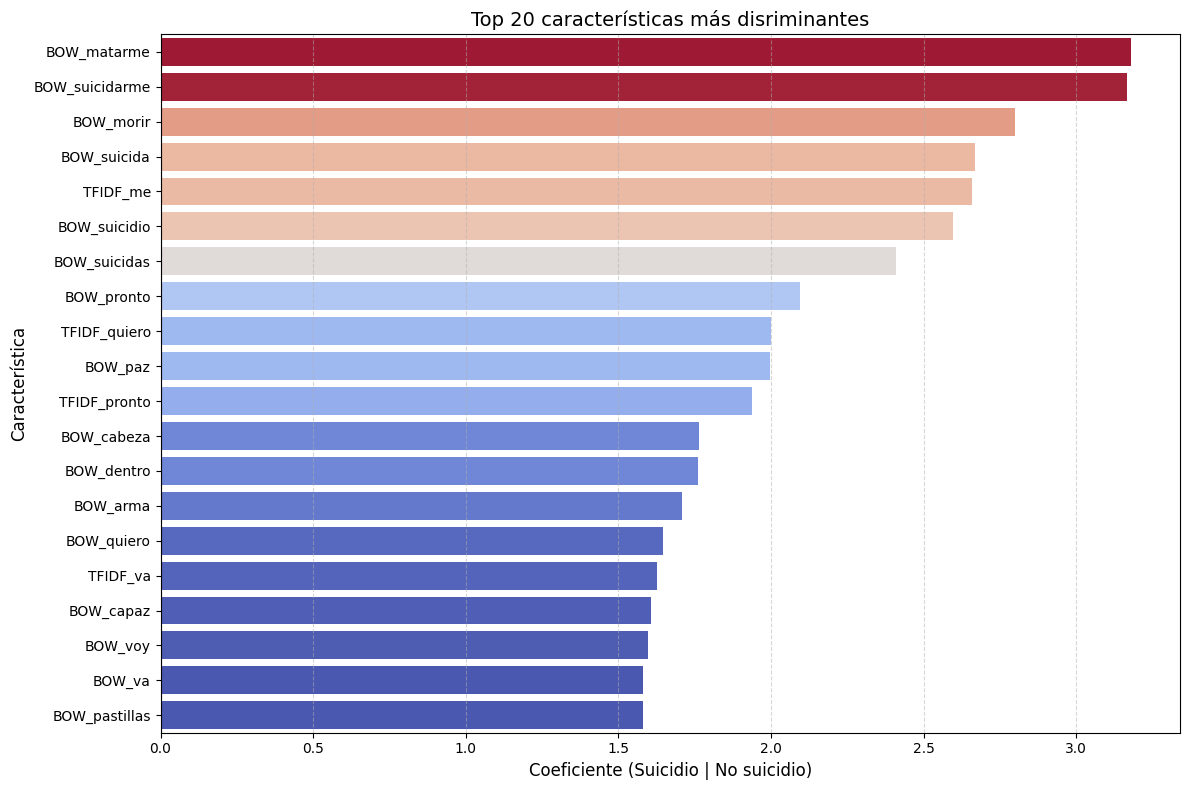

In [ ]:
###### Extracción de características más discriminantes ######

# Guardamos el nombre de cada característica en varaible
feature_union = pipeline_clasificador.named_steps['union_caracteristicas']

# Extraemos los nombres de cada características (técnicas empleadas)
bow_features = [f"BOW_{name}" for name in feature_union.transformer_list[0][1].get_feature_names_out()]
tfidf_features = [f"TFIDF_{name}" for name in feature_union.transformer_list[1][1].get_feature_names_out()]
ngrams_bow_features = [f"Ngram_BOW_{name}" for name in feature_union.transformer_list[2][1].get_feature_names_out()]
ngrams_tfidf_features = [f"Ngram_TFIDF_{name}" for name in feature_union.transformer_list[3][1].get_feature_names_out()]

# Características personales (Información lingüística)
linguistic_features = ['Longitud_Texto', 'Polaridad_Sentimiento', 'Num_Verbos', 'Num_Nombres_Propios']

# Unimos todos los nombres de características en orden
todas_las_caracteristicas = np.array(
    bow_features + tfidf_features + ngrams_bow_features + ngrams_tfidf_features + linguistic_features
)

# Extraemos los coeficientes del clasificador (Regresión Logística)
coeficientes = pipeline_clasificador.named_steps['clasificador'].coef_[0]

# Creamos un DataFrame con los coeficientes ordenados
df_importancia = pd.DataFrame({
    'Característica': todas_las_caracteristicas,
    'Coeficiente': coeficientes,
    'Magnitud_Absoluta': np.abs(coeficientes)
}).sort_values(by='Magnitud_Absoluta', ascending=False)

# Top N de características (instancias) más discriminantes
print("=== Top N de características más discriminantes ===")
display(df_importancia.head(20))

# Visualización de las N características más discriminantes
top_20_plot = df_importancia.head(20).sort_values(by='Coeficiente', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(
    x='Coeficiente',
    y='Característica',
    data=top_20_plot,
    palette='coolwarm',
    hue='Coeficiente',
    legend=False
)
plt.axvline(x=0, color='black', linestyle='--', alpha=0.7)
plt.title('Top 20 características más disriminantes', fontsize=14)
plt.xlabel('Coeficiente (Suicidio | No suicidio)', fontsize=12)
plt.ylabel('Característica', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Optimización

Es importante destacar que este tipo de modelos puede entrenarse con parámetros optimizados con el fin de mejorar el entrenamiento del modelo y su posterior uso. En este caso, vamos a optimizar algunos de estos parámetros para evaluar qué tanto puede mejorar el modelo haciendo ajustes mínimos.

El primero de estos ajustes será elevar el umbral de clasificación. Durante el entrenamiento se usaron los parámetros base de ambos clasificadores: Bayes (para evaluar las características de las primeras técnicas) y Regresión logística (para evaluar las características totales). En ambos casos, estos parámetros base parten de una distribución balanceada, lo que se traduce en un umbral más permisivo y que no tiene un correlato real con la distribución de clases (9 a 1). En este ajuste vamos a elevar el umbral de clasificación a un punto más cercano a la distribución de los datos.

Map:   0%|          | 0/3015 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Reporte de clasificación con umbrar optimizado
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      2778
           1       0.81      0.83      0.82       237

    accuracy                           0.97      3015
   macro avg       0.90      0.91      0.90      3015
weighted avg       0.97      0.97      0.97      3015



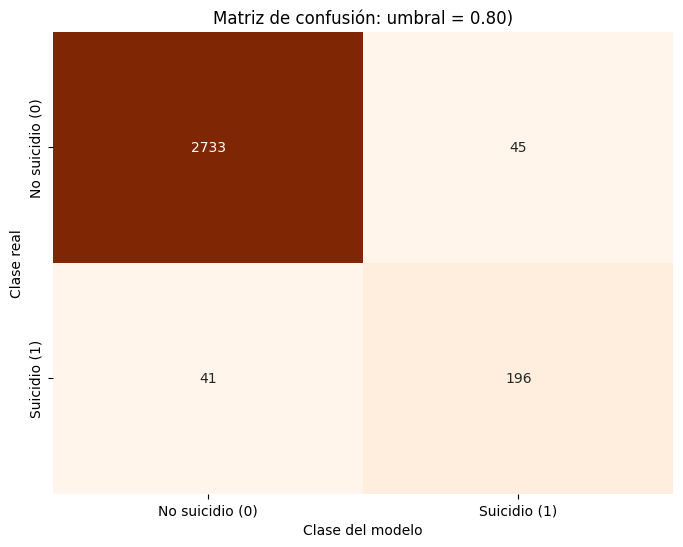

In [ ]:
####### Ajuste de umbral ######

# Definimos una función que modifique el umbral de clasificación. En este caso, lo establecermos en 0.80
class ThresholdedClassifierPipeline:
    def __init__(self, pipeline, threshold=0.80):
        self.pipeline = pipeline
        self.threshold = threshold

    def predict(self, X):
        # Obtenemos las probabilidades estimadas para la clase positiva (1)
        probs = self.pipeline.predict_proba(X)[:, 1]
        return (probs >= self.threshold).astype(int)

    def predict_proba(self, X):
        return self.pipeline.predict_proba(X)

# Instanciamos el modelo con el umbral que establecimos
modelo_optimizado = ThresholdedClassifierPipeline(pipeline_clasificador, threshold=0.80)

# Entrenamos con el mismo conjunto de prueba
y_pred_produccion = modelo_optimizado.predict(x_test)

# Reporte de clasificación
print("="*60)
print("Reporte de clasificación con umbrar optimizado")
print("="*60)
print(classification_report(y_test, y_pred_produccion))

# Matriz de confusión
cm_produccion = confusion_matrix(y_test, y_pred_produccion)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_produccion, annot=True, fmt='d', cmap='Oranges', cbar=False,
            xticklabels=['No suicidio (0)', 'Suicidio (1)'],
            yticklabels=['No suicidio (0)', 'Suicidio (1)'])
plt.title('Matriz de confusión: umbral = 0.80)')
plt.ylabel('Clase real')
plt.xlabel('Clase del modelo')
plt.show()

Impacto absoluto máximo de una palabra: 3.1805
Impacto absoluto promedio de las características de texto: 0.1883



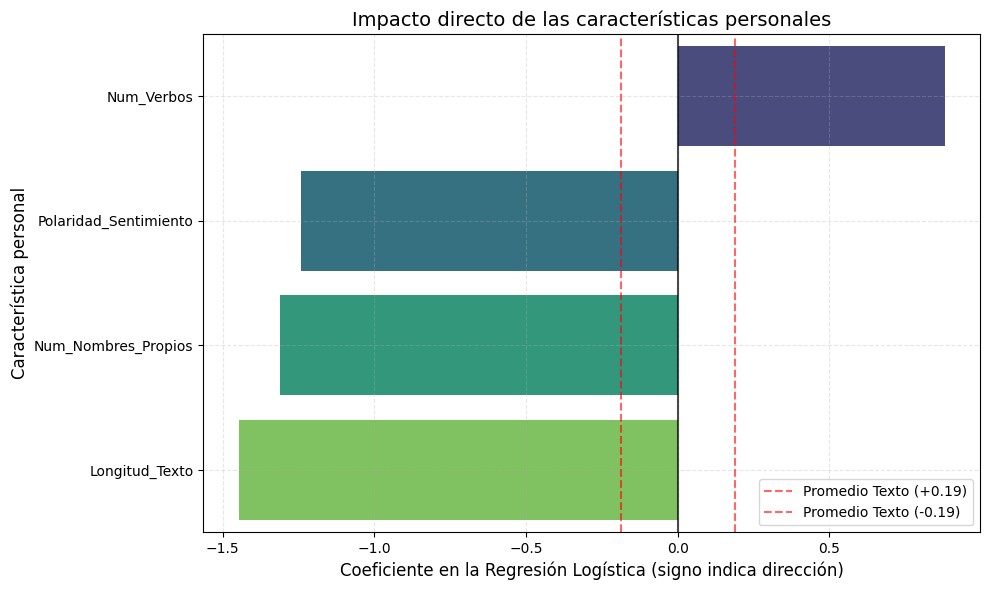

In [ ]:
###### Extracción de características personales más disriminantes con modelo optimizado ######

# Identificamos cuáles son las características personales
linguisticas_list = ['Longitud_Texto', 'Polaridad_Sentimiento', 'Num_Verbos', 'Num_Nombres_Propios']
df_importancia_ling = df_importancia[df_importancia['Característica'].isin(linguisticas_list)].copy()

# Calculamos el promedio de importancia del resto de características de texto para tener una base de referencia
df_texto = df_importancia[~df_importancia['Característica'].isin(linguisticas_list)]
promedio_texto_abs = df_texto['Magnitud_Absoluta'].mean()
max_texto_abs = df_texto['Magnitud_Absoluta'].max()

print(f"Impacto absoluto máximo de una palabra: {max_texto_abs:.4f}")
print(f"Impacto absoluto promedio de las características de texto: {promedio_texto_abs:.4f}\n")

# Graficamos el peso e impacto directo de nuestras variables lingüísticas
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Coeficiente',
    y='Característica',
    data=df_importancia_ling.sort_values(by='Coeficiente', ascending=False),
    palette='viridis',
    hue='Característica',
    legend=False
)
plt.axvline(x=0, color='black', linestyle='-', alpha=0.7)
# Añadir líneas de referencia con el promedio del impacto de texto tradicional
plt.axvline(x=promedio_texto_abs, color='red', linestyle='--', alpha=0.6, label=f'Promedio Texto (+{promedio_texto_abs:.2f})')
plt.axvline(x=-promedio_texto_abs, color='red', linestyle='--', alpha=0.6, label=f'Promedio Texto (-{promedio_texto_abs:.2f})')

plt.title('Impacto directo de las características personales', fontsize=14)
plt.xlabel('Coeficiente en la Regresión Logística (signo indica dirección)', fontsize=12)
plt.ylabel('Característica personal', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

## Análisis de errores (Falsos Positivos y Falsos Negativos)

Otro punto importante en este tipo de aproximaciones es el análisis de errores. A partir de la identificación de aquello que está haciendo ruido, podemos mejorar el entendimiento del fenómeno y, con ello, el conjunto de características que integran el modelo.

A continuación, vamos a extraer los documentos del conjunto de test en  donde el modelo cometió errores de clasificación. **Nota**: Recordar que esta partición no se debe ver/analizar, pues es la que nos sirve de control.

El análisis de errores se hará considernando el modelo optimizado a partir de la extracción de los FP y FN. Este proceso nos permitirá comprender las limitaciones actuales del modelo, así como las sutilezas lingüísticas o semánticas que confunden al algoritmo.

In [ ]:
# Calculamos las probabilidades del modelo unificado
y_probs_test = pipeline_clasificador.predict_proba(x_test)[:, 1]

# Aplicamos el umbral optimizado
y_pred_prod = (y_probs_test >= 0.80).astype(int)

# Construimos un DF para sistematizar los datos
df_analisis_errores = pd.DataFrame({
    'Documento': x_test,
    'Clase_Real': y_test,
    'Prediccion_Modelo': y_pred_prod,
    'Probabilidad_Riesgo': y_probs_test
})

# Filtramos los FN (Real: 1 | Modelo: 0)
falsos_negativos = df_analisis_errores[
    (df_analisis_errores['Clase_Real'] == 1) & (df_analisis_errores['Prediccion_Modelo'] == 0)
].sort_values(by='Probabilidad_Riesgo', ascending=False)

# Filtramos los FP (Real: 0 | Modelo: 1)
falsos_positivos = df_analisis_errores[
    (df_analisis_errores['Clase_Real'] == 0) & (df_analisis_errores['Prediccion_Modelo'] == 1)
].sort_values(by='Probabilidad_Riesgo', ascending=True)

print(f"Cantidad total de Falsos Negativos (Notas omitidas): {len(falsos_negativos)}")
print(f"Cantidad total de Falsos Positivos (Falsas alarmas): {len(falsos_positivos)}")

Map:   0%|          | 0/3015 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Cantidad total de Falsos Negativos (Notas omitidas): 41
Cantidad total de Falsos Positivos (Falsas alarmas): 45


### Ejemplos de Falsos Negativos

In [ ]:
# N ejemplos de FN (notas omitidas)

print("=== Ejemplos de FN  ===\n")
for i, (idx, row) in enumerate(falsos_negativos.head(10).iterrows(), 1):
    print(f"[{i}] ID: {idx} | Probabilidad de riesgo estimada: {row['Probabilidad_Riesgo']:.2%}")
    print(f"Documento: {row['Documento']}")
    print("-" * 90 + "\n")

### Ejemplos de Falsos Positivos

In [ ]:
# N ejemplos de FP
print("=== Ejempos de FP ===\n")
for i, (idx, row) in enumerate(falsos_positivos.head(10).iterrows(), 1):
    print(f"[{i}] ID: {idx} | Probabilidad de riesgo estimada: {row['Probabilidad_Riesgo']:.2%}")
    print(f"Documento: {row['Documento']}")
    print("-" * 90 + "\n")

Una vez que tenemos los ejemplos que nos pueden ayudar a entender con mayor profundidad el fenómeno y mejorar el modelo, podemos crear una matriz de confusión enriquecida para incorporarla a nuestro reporte y hacer que la lectura sea más fácil de comprender y divulgativa.

Map:   0%|          | 0/3015 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


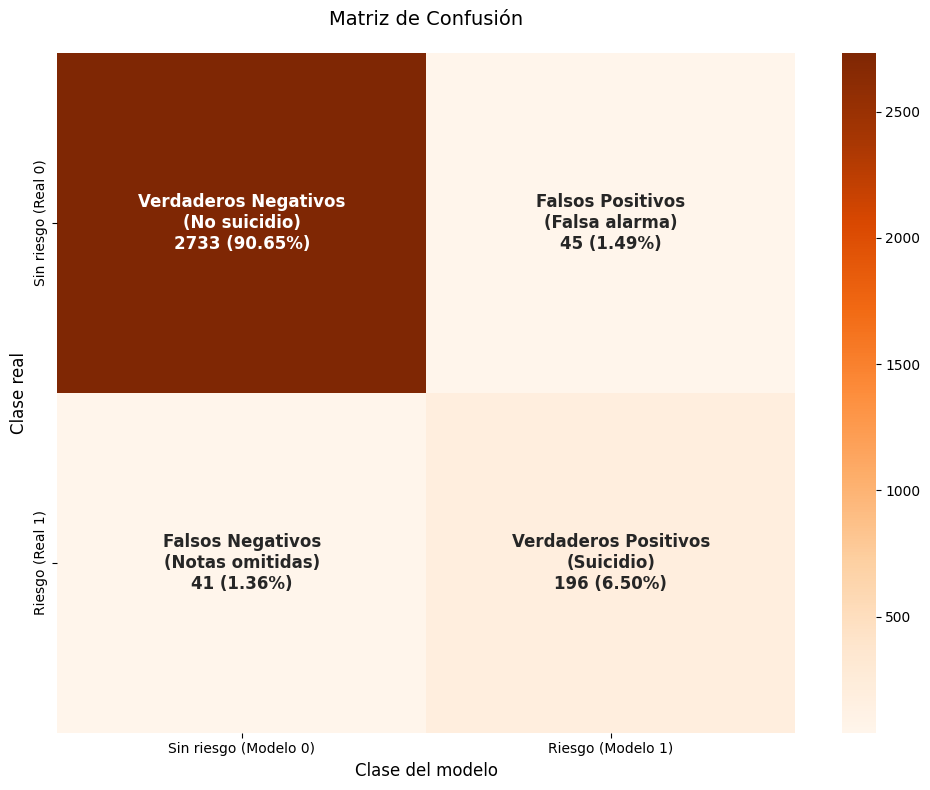

In [ ]:
###### Matriz de confusión enriquecida ######

# Obtener las predicciones del modelo definitivo
y_pred_produccion = modelo_optimizado.predict(x_test)

# 2. Calcular la matriz de confusión
cm_prod = confusion_matrix(y_test, y_pred_produccion)

# 3. Diseñar las etiquetas internas para la matriz de confusión
group_names = ['Verdaderos Negativos\n(No suicidio)', 'Falsos Positivos\n(Falsa alarma)', 'Falsos Negativos\n(Notas omitidas)', 'Verdaderos Positivos\n(Suicidio)']
group_counts = ["{0:0.0f}".format(value) for value in cm_prod.flatten()]
group_percentages = ["{0:.2%}".format(value) for value in cm_prod.flatten()/np.sum(cm_prod)]

labels = [f"{v1}\n{v2} ({v3})" for v1, v2, v3 in zip(group_names, group_counts, group_percentages)]
labels = np.asarray(labels).reshape(2,2)

# Matriz de confusión
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm_prod,
    annot=labels,
    fmt='',
    cmap='Oranges',
    cbar=True,
    xticklabels=['Sin riesgo (Modelo 0)', 'Riesgo (Modelo 1)'],
    yticklabels=['Sin riesgo (Real 0)', 'Riesgo (Real 1)'],
    annot_kws={"size": 12, "weight": "bold"}
)

plt.title('Matriz de Confusión', fontsize=14, pad=20)
plt.ylabel('Clase real', fontsize=12)
plt.xlabel('Clase del modelo', fontsize=12)
plt.tight_layout()
plt.show()

## Curva ROC

Representación gráfica que evalúa el rendimiento de un modelo de clasificación. Toma como parámetro fundamental, el Recall.


In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve, auc, average_precision_score

# Calculamos las métricas numéricas acumuladas
auc_roc = roc_auc_score(y_test, y_probs_test)
ap_score = average_precision_score(y_test, y_probs_test)

print("=" * 50)
print("Métricas de discriminación")
print("=" * 50)
print(f"Área Bajo la Curva ROC (AUC-ROC): {auc_roc:.4f}")
print(f"Precisión Promedio (AP / PR-AUC): {ap_score:.4f}")
print("=" * 50)

# Obtenemos los vectores de la Curva ROC
fpr, tpr, thresholds_roc = roc_curve(y_test, y_probs_test)

# Graficamos
plt.figure(figsize=(10, 7))
plt.plot(fpr, tpr, color='darkorange', lw=3, label=f'Curva ROC (AUC = {auc_roc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Clasificador aleatorio (AUC = 0.50)')

# Ubicar visualmente el punto de operación de nuestro umbral óptimo (0.80)
idx_umbral = np.argmin(np.abs(thresholds_roc - 0.80))
plt.scatter(fpr[idx_umbral], tpr[idx_umbral], color='red', s=150, zorder=5, edgecolor='black',
            label=f'Umbral optimizado (0.80)\n(FPR: {fpr[idx_umbral]:.2%}, TPR/Recall: {tpr[idx_umbral]:.2%})')

plt.xlim([-0.02, 1.02])
plt.ylim([-0.02, 1.02])
plt.xlabel('Tasa de Falsos Positivos (FPR / 1 - Especificidad)', fontsize=12)
plt.ylabel('Tasa de Verdaderos Positivos (TPR / Sensibilidad)', fontsize=12)
plt.title('Curva ROC - Modelo unificado', fontsize=14, pad=15)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc="lower right", fontsize=11)
plt.tight_layout()
plt.show()

## Informe

Este informe detalla las métricas de evaluación del modelo unificadoy evaluado con el conjunto de test ($N = 3015$ documentos).

### 1. Tabla de Métricas Consolidadas

| Clase / Etiqueta | Precisión (Precision) | Sensibilidad (Recall) | F1-Score | Soporte (Muestras) |
| :--- | :---: | :---: | :---: | :---: |
| **Clase 0: No suidicio** | 98.70% | 98.13% | 98.41% | 2,778 |
| **Clase 1: Suicidio** | **79.45%** | **84.81%** | **82.04%** | 237 |
| **Accuracy** | | | **97.08%** | 3,015 |

---

### 2. Puntos a considerar

* ** Precisión +79.45%**: la elevación del umbral de decisión a **0.80** impacta favorablemente, puesto que el modelo identifica, aproximadamente **4 de cada 5 ** notas de suicidio.
* ** Recall  +84.81%**: el modelo logra identificar de manera eficiente un porcentaje alto de notas de suicidio, dejando únicamente una fracción pequeña de casos sin clasificar (Falsos Negativos).
* **Rendimiento general (+97.08% de accuracy)**: La combinación de características léxicas clásicas (BOW y TF-IDF de n-gramas) con rasgos estructurales profundos (polaridad continua por Transformers y morfología spaCy) dota al modelo de una gran capacidad de generalización ante variaciones textuales.

### Modelo para producción

Vamos a configurar un modelo final con un umbral optimizado pensando en que puede ser implementado en escenarios reales.
Para ello, vamos a establecer como valor óptimo el umbral de decisión en **0.80**.

**Nota**: en este ejercicio no experimentamos con otros umbrales; lo ideal sería hacerlo, aunque ello implique un coste temporal alto, para definir el umbral adecuado.

In [ ]:
import dill
from sklearn.metrics import classification_report, confusion_matrix

# Definimos un función con el umbral óptimo de 0.80
class ThresholdedClassifierPipeline:
    def __init__(self, pipeline, threshold=0.80):
        self.pipeline = pipeline
        self.threshold = threshold

    def predict(self, X):
        # Obtener probabilidades de la clase positiva (1)
        probs = self.pipeline.predict_proba(X)[:, 1]
        return (probs >= self.threshold).astype(int)

    def predict_proba(self, X):
        return self.pipeline.predict_proba(X)

# Instanciamos el modelo de producción
modelo_final_produccion = ThresholdedClassifierPipeline(pipeline_clasificador, threshold=0.80)

# Guardamos el modelo entrenado
with open('pipeline_suicidio_umbral_080.pkl', 'wb') as f:
    dill.dump(modelo_final_produccion, f)
print("Modelo de producción exportado exitosamente")

# Evaluación oficial de control con el umbral de producción (corregido usando x_test)
y_pred_produccion = modelo_final_produccion.predict(x_test)
print("\n" + "="*60)
print(" Reporte final de modelo de producción (umbral = 0.80)")
print("="*60)
print(classification_report(y_test, y_pred_produccion))

Modelo de producción exportado exitosamente


Map:   0%|          | 0/3015 [00:00<?, ? examples/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



 Reporte final de modelo de producción (umbral = 0.80)
              precision    recall  f1-score   support

           0       0.99      0.98      0.98      2778
           1       0.81      0.83      0.82       237

    accuracy                           0.97      3015
   macro avg       0.90      0.91      0.90      3015
weighted avg       0.97      0.97      0.97      3015

